# 02 · Model comparison under k-fold cross validation

Every model is evaluated on **the same fold assignment**, which is what makes
the paired significance test at the end legitimate.

In [1]:
# --- Google Colab setup (skipped when running locally) ---------------------
# Clones the repository, installs the dependencies and downloads the Jigsaw data.
# Kaggle needs an API token: store it under Colab "Secrets" as KAGGLE_API_TOKEN
# and accept the competition rules on kaggle.com first.  Without it the
# notebook falls back to synthetic data, whose numbers must not be reported.
import os, subprocess, sys

if "google.colab" in sys.modules:
    REPO = "/content/Seminar-2"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "https://github.com/ktcshust/Seminar-2", REPO], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "-r", f"{REPO}/requirements.txt", "kagglehub"], check=True)
    try:
        from google.colab import userdata
        os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    except Exception:
        print("No KAGGLE_API_TOKEN secret found.")
    subprocess.run([sys.executable, f"{REPO}/scripts/download_data.py"], check=False)
    os.chdir(f"{REPO}/notebooks")

In [2]:
import sys, warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

from src.config import Config

# `memory` keeps this session's intermediate frames out of the file system;
# switch to "file" to persist them under data/processed/.
CONFIG = Config(persistence_backend="memory")
CONFIG.ensure_directories()
CONFIG.label_columns

('toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate')

In [3]:
from src.dataio import load_training_data, raw_files_available

# allow_synthetic keeps the notebook runnable before the Kaggle download;
# every number below is only meaningful once raw_files_available() is True.
train = load_training_data(config=CONFIG, allow_synthetic=True)
print("real dataset:", raw_files_available(), "| rows:", len(train))
train.head(3)

real dataset: True | rows: 159571


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0


In [4]:
from src.dataio import label_matrix, stratified_subsample, texts

# Drop to a stratified subsample while iterating; remove for the final run.
SAMPLE_SIZE = 20_000
frame = stratified_subsample(train, SAMPLE_SIZE, config=CONFIG) if len(train) > SAMPLE_SIZE else train

comment_text = texts(frame, CONFIG).tolist()
y = label_matrix(frame, CONFIG)
label_names = list(CONFIG.label_columns)
print(f"{len(frame)} comments, positive rate per label:")
print(pd.Series(y.mean(axis=0), index=label_names).round(4))

20000 comments, positive rate per label:
toxic            0.0958
severe_toxic     0.0104
obscene          0.0528
threat           0.0028
insult           0.0505
identity_hate    0.0092
dtype: float64


## Fold construction

`iterative` means the `iterative-stratification` package balanced all six labels
across the folds; `label_powerset` is the fallback. **Record which one ran** —
they are not interchangeable.

In [5]:
from src.evaluation import make_multilabel_folds

folds, strategy = make_multilabel_folds(y, n_splits=CONFIG.n_splits,
                                        random_state=CONFIG.random_state)
print("strategy:", strategy, "| folds:", len(folds))

# Check the rare labels survived the split.
fold_rates = pd.DataFrame(
    [y[validation].mean(axis=0) for _, validation in folds],
    columns=label_names, index=[f"fold {i}" for i in range(1, len(folds) + 1)],
)
display(fold_rates.style.format("{:.4f}"))

strategy: iterative | folds: 5


,toxic,severe_toxic,obscene,threat,insult,identity_hate
fold 1,0.0958,0.0105,0.0527,0.0027,0.0505,0.0092
fold 2,0.0958,0.0103,0.0527,0.0027,0.0505,0.0092
fold 3,0.0960,0.0103,0.0527,0.0027,0.0505,0.0092
fold 4,0.0958,0.0105,0.0527,0.0027,0.0505,0.0092
fold 5,0.0960,0.0103,0.0527,0.0027,0.0505,0.0092


## Cross-validating every model

In [6]:
from src.evaluation import cross_validate_model
from src.models import build_model, lightweight_models

MODELS = lightweight_models()   # add "distilbert" once requirements-dl.txt is installed
results = {}

for name in MODELS:
    print(f"--- {name} ---")
    results[name] = cross_validate_model(
        model_factory=lambda name=name: build_model(name, label_names=label_names),
        texts=comment_text, y=y, label_names=label_names,
        folds=folds, strategy=strategy, random_state=CONFIG.random_state,
    )
    print(results[name].summary[["mean_column_auc_mean", "macro_f1_mean"]].round(4).to_dict())

--- prior ---


{'mean_column_auc_mean': 0.5, 'macro_f1_mean': 0.0653}
--- keyword ---


{'mean_column_auc_mean': 0.7874, 'macro_f1_mean': 0.2554}
--- logreg ---


{'mean_column_auc_mean': 0.9728, 'macro_f1_mean': 0.5984}
--- nbsvm ---


{'mean_column_auc_mean': 0.9651, 'macro_f1_mean': 0.5703}
--- linear_svm ---


{'mean_column_auc_mean': 0.965, 'macro_f1_mean': 0.5907}


## Leaderboard

,mean_column_auc_mean,mean_column_auc_std,mean_column_pr_auc_mean,macro_f1_mean,micro_f1_mean,subset_accuracy_mean,fit_seconds_mean
logreg,0.9728,0.0093,0.6327,0.5984,0.7221,0.9072,14.9112
nbsvm,0.9651,0.0098,0.6021,0.5703,0.7346,0.9162,12.2404
linear_svm,0.9650,0.0109,0.6236,0.5907,0.7215,0.9102,8.9459
keyword,0.7874,0.0184,0.1353,0.2554,0.2902,0.8295,0.0519
prior,0.5000,0.0000,0.0369,0.0653,0.0992,0.0066,0.0007


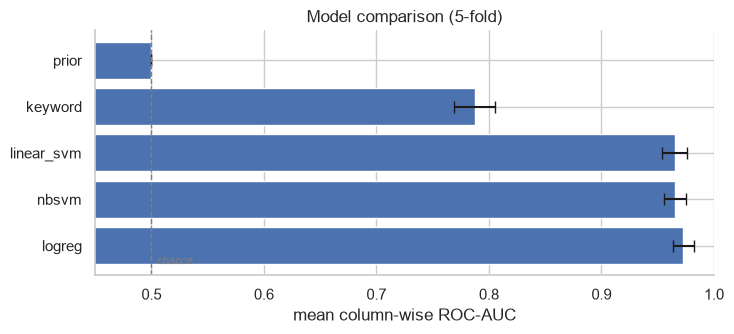

In [7]:
leaderboard = (
    pd.DataFrame([result.summary for result in results.values()])
    .sort_values("mean_column_auc_mean", ascending=False)
)
display(
    leaderboard[[
        "mean_column_auc_mean", "mean_column_auc_std", "mean_column_pr_auc_mean",
        "macro_f1_mean", "micro_f1_mean", "subset_accuracy_mean", "fit_seconds_mean",
    ]].round(4)
)

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.barh(leaderboard.index, leaderboard["mean_column_auc_mean"],
        xerr=leaderboard["mean_column_auc_std"], color="#4C72B0", capsize=4)
ax.axvline(0.5, color="grey", ls="--", lw=1)
ax.text(0.505, -0.4, "chance", color="grey", fontsize=8)
ax.set(xlabel="mean column-wise ROC-AUC", xlim=(0.45, 1.0), title="Model comparison (5-fold)")
sns.despine(ax=ax)
fig.tight_layout()
fig.savefig(CONFIG.figures_dir / "notebook_leaderboard.png", dpi=200)

## Per-label breakdown

The aggregate hides the interesting part: the rare labels are where the models
actually differ.

,support,positive_rate,roc_auc,pr_auc,precision,recall,f1,threshold
label,,,,,,,,
toxic,383.4,0.0958,0.9687,0.8556,0.7878,0.7392,0.7590,0.5255
severe_toxic,41.4,0.0104,0.9866,0.4886,0.4594,0.4973,0.4635,0.7078
obscene,211.0,0.0528,0.9840,0.8776,0.8191,0.7829,0.7995,0.5039
threat,11.0,0.0028,0.9695,0.3941,0.5116,0.4364,0.4592,0.3785
insult,202.0,0.0505,0.9749,0.7733,0.7101,0.7198,0.7108,0.5353
identity_hate,37.0,0.0092,0.9532,0.4068,0.3908,0.4486,0.3984,0.4510


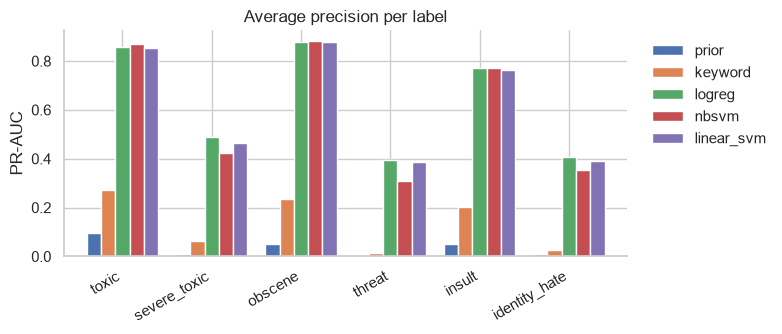

In [8]:
best = leaderboard.index[0]
display(results[best].label_summary.round(4))

comparison = pd.DataFrame(
    {name: result.label_summary["pr_auc"] for name, result in results.items()}
)
fig, ax = plt.subplots(figsize=(8, 3.5))
comparison.plot.bar(ax=ax, width=0.8)
ax.set(ylabel="PR-AUC", xlabel="", title="Average precision per label")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.xticks(rotation=30, ha="right")
sns.despine(ax=ax)
fig.tight_layout()
fig.savefig(CONFIG.figures_dir / "notebook_pr_auc_per_label.png", dpi=200)

## Is the difference real?

With five folds the Wilcoxon test bottoms out at p = 0.0625, so no pairwise
difference can reach the 5% level however large it is. Report the effect size
next to the p-value, and increase the number of folds if the claim matters.

In [9]:
from src.evaluation import comparison_matrix, paired_comparison

matrix = comparison_matrix({name: result.fold_scores() for name, result in results.items()})
print(f"Bonferroni-corrected alpha = {matrix.attrs['bonferroni_alpha']:.4f}")
display(matrix.round(4))

runner_up = leaderboard.index[1]
best_vs_second = paired_comparison(
    results[best].fold_scores(), results[runner_up].fold_scores(), best, runner_up
)
pd.Series(best_vs_second.to_dict())

Bonferroni-corrected alpha = 0.0050


,prior,keyword,logreg,nbsvm,linear_svm
prior,1.0000,0.0625,0.0625,0.0625,0.0625
keyword,0.0625,1.0000,0.0625,0.0625,0.0625
logreg,0.0625,0.0625,1.0000,0.0625,0.0625
nbsvm,0.0625,0.0625,0.0625,1.0000,1.0000
linear_svm,0.0625,0.0625,0.0625,1.0000,1.0000


model_a              logreg
model_b               nbsvm
mean_a              0.97282
mean_b             0.965146
mean_difference    0.007674
cohens_d           5.201185
wilcoxon_p           0.0625
ttest_p            0.000312
n_folds                   5
significant           False
dtype: object

## Cost against accuracy

The practical question a deployment team asks.

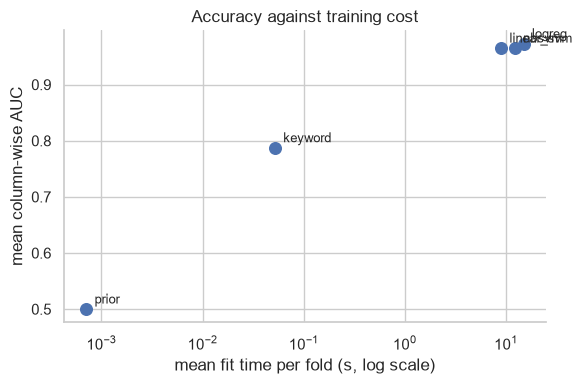

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(leaderboard["fit_seconds_mean"], leaderboard["mean_column_auc_mean"], s=70)
for name, row in leaderboard.iterrows():
    ax.annotate(name, (row["fit_seconds_mean"], row["mean_column_auc_mean"]),
                textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set(xscale="log", xlabel="mean fit time per fold (s, log scale)",
       ylabel="mean column-wise AUC", title="Accuracy against training cost")
sns.despine(ax=ax)
fig.tight_layout()
fig.savefig(CONFIG.figures_dir / "notebook_cost_vs_accuracy.png", dpi=200)

## Persist the results

Stored through the artifact repository, so this cell is backend-agnostic.

In [11]:
from src.repository import get_artifact_repository

artifacts = get_artifact_repository(Config(persistence_backend="file"))
for name, result in results.items():
    artifacts.save(f"notebook_{name}", result.to_dict())
artifacts.save("notebook_leaderboard", leaderboard.reset_index(names="model").to_dict("records"))
artifacts.list_artifacts()

['experiment_bias',
 'experiment_hierarchy',
 'experiment_keyword',
 'experiment_leaderboard',
 'experiment_linear_svm',
 'experiment_logreg',
 'experiment_metadata',
 'experiment_nbsvm',
 'experiment_oof_predictions',
 'experiment_oof_scores',
 'experiment_prior',
 'experiment_significance',
 'notebook_keyword',
 'notebook_leaderboard',
 'notebook_linear_svm',
 'notebook_logreg',
 'notebook_nbsvm',
 'notebook_prior',
 'smoke_bias',
 'smoke_hierarchy',
 'smoke_keyword',
 'smoke_leaderboard',
 'smoke_linear_svm',
 'smoke_logreg',
 'smoke_metadata',
 'smoke_nbsvm',
 'smoke_oof_predictions',
 'smoke_oof_scores',
 'smoke_prior',
 'smoke_significance']